In [71]:
#import all 

import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
pd.options.display.float_format = "{:,.2f}".format

In [9]:
#import download files from kaggle 

path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)
print(os.listdir(path))

Path to dataset files: /Users/Julian/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3
['amz_uk_price_prediction_dataset.csv']


In [10]:
### load dataset
df = pd.read_csv(os.path.join(path, "amz_uk_price_prediction_dataset.csv"))

In [24]:
#inspect data

display(df.head())
display(df.info())
display(df.shape)
display(df.columns)
display(df.describe())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


None

(2443651, 9)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

,uid,stars,reviews,price,boughtInLastMonth
count,"2,443,651.00","2,443,651.00","2,443,651.00","2,443,651.00","2,443,651.00"
mean,"1,370,545.35",2.15,480.63,89.24,25.90
std,"816,056.17",2.19,"5,944.12",345.61,240.48
min,1.00,0.00,0.00,0.00,0.00
25%,"658,921.50",0.00,0.00,9.99,0.00
50%,"1,349,029.00",0.00,0.00,19.09,0.00
75%,"2,060,685.50",4.40,59.00,45.99,0.00
max,"2,828,593.00",5.00,"1,356,658.00","100,000.00","50,000.00"


+++ PART 1: UNderstanding Product Category

In [12]:
#figure out details of the category 

display(df["category"].isna().sum())
display(df["category"].nunique())
display(df["category"].value_counts())


np.int64(0)

296

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [13]:
category_freq = (
    df["category"]
    .value_counts().reset_index()
)

category_freq.columns = ["category", "listing_count"]

category_freq["percentage"] = (
                                category_freq["listing_count"] / len(df) * 100
)

top_5_categories = category_freq.head(5)


In [14]:
top_5_categories

,category,listing_count,percentage
0,Sports & Outdoors,836265,34.221949
1,Beauty,19312,0.790293
2,"Handmade Clothing, Shoes & Accessories",19229,0.786896
3,Bath & Body,19092,0.781290
4,Birthday Gifts,18978,0.776625


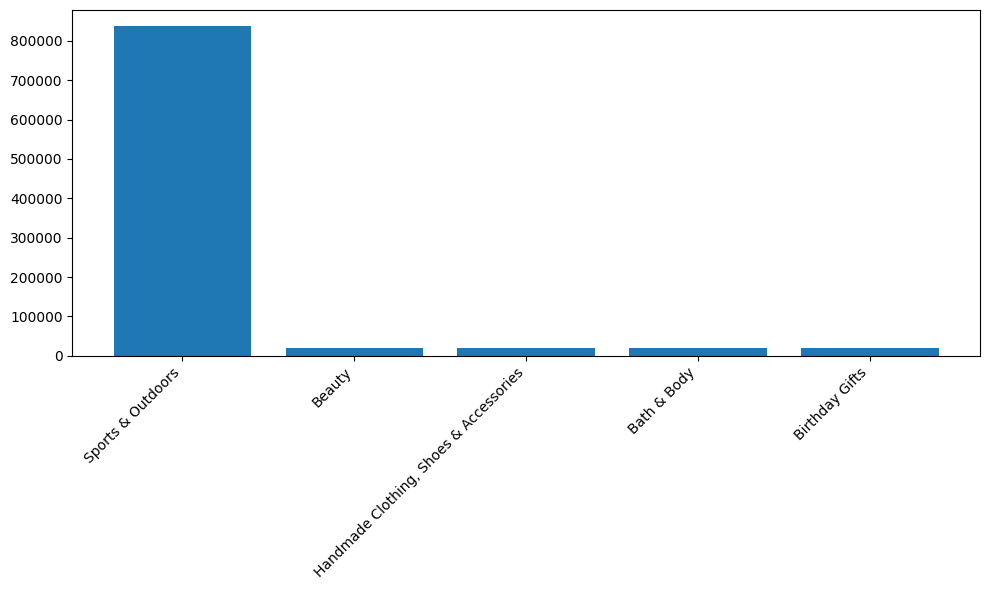

In [21]:
#visualize above stuff


plt.figure(figsize=(10, 6))
plt.bar(top_5_categories["category"], top_5_categories["listing_count"] )
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Part 2: Delving into Product Price


In [22]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
#price data details - is it good

display(df["price"].isna().sum())
display((df["price"] <= 0).sum()) #arround 20 in negative .. negegible over 2MM entries .. lets see what happens with std


np.int64(0)

np.int64(20)

In [42]:
# measure of Centrallity
mean_price = df["price"].mean()
meadian_price = df["price"].median()
mode_price = df["price"].mode()[0] ### need the zero to pull the most common one .. usually have multioke values as it is price point 



display(mean_price)
display(meadian_price)
display(mode_price)


np.float64(89.24380943923661)

np.float64(19.09)

np.float64(9.99)

In [45]:
#measure of Dispersion 


price_variance = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min() 
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1




display(price_variance)
display(price_std)
display(price_range)
display(q1)
display(q3)
display(iqr)



np.float64(119445.48532254901)

np.float64(345.60886175349873)

np.float64(100000.0)

np.float64(9.99)

np.float64(45.99)

np.float64(36.0)

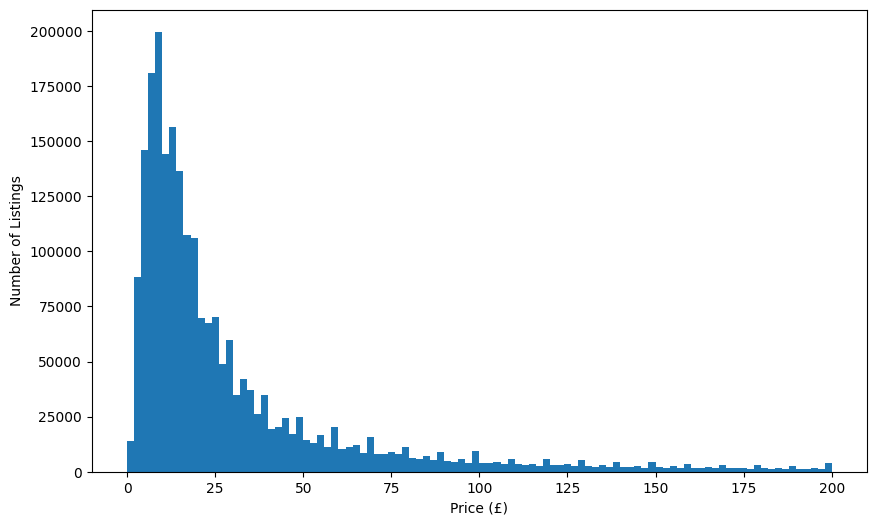

In [52]:
## visualize info 

plt.figure(figsize=(10, 6))
plt.hist(df[df["price"] <= 200]["price"], bins=100)
plt.xlabel("Price (£)")
plt.ylabel("Number of Listings")
plt.show()

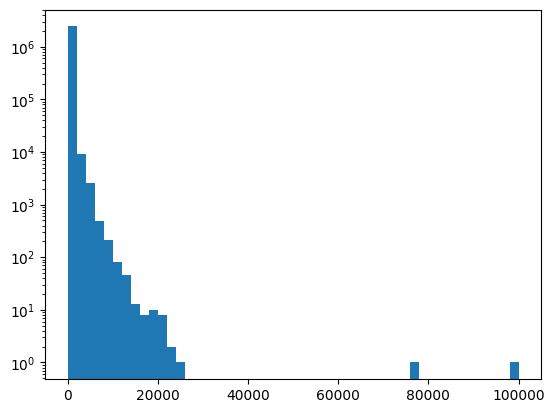

In [55]:
### include everything 

plt.hist(df["price"], bins=50)
plt.yscale("log")

{'whiskers': [<matplotlib.lines.Line2D at 0x13b265d10>,
 'caps': [<matplotlib.lines.Line2D at 0x13b265f90>,
 'boxes': [<matplotlib.lines.Line2D at 0x13b265bd0>],
 'medians': [<matplotlib.lines.Line2D at 0x13b266210>],
 'fliers': [<matplotlib.lines.Line2D at 0x13b266350>],
 'means': []}

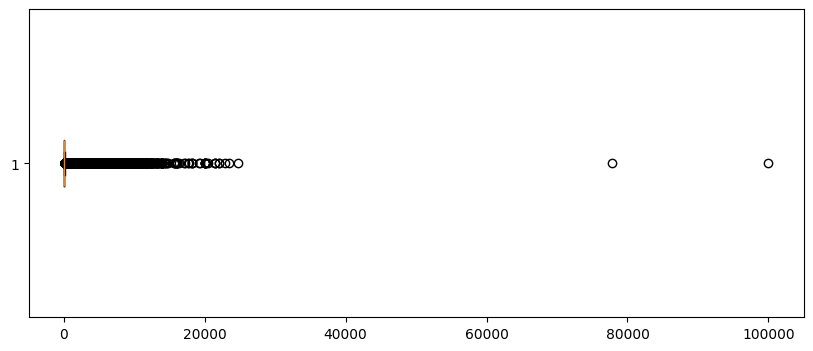

In [63]:
#look at box plat 
plt.figure(figsize=(10, 4))
plt.boxplot(df["price"], vert=False)

+++ Question 3: unpacking product rating 

In [68]:
#check cells 


mode_rating = df["stars"].mode()
var_rating = df["stars"].var()


display(df["stars"].isna().sum())
display(df["stars"].describe())
display(mode_rating)
display(var_rating)


np.int64(0)

count   2,443,651.00
mean            2.15
std             2.19
min             0.00
25%             0.00
50%             0.00
75%             4.40
max             5.00
Name: stars, dtype: float64

0   0.00
Name: stars, dtype: float64

np.float64(4.817434029796864)

In [ ]:
#shape of distribution 

skewness = df["stars"].skew()
kurtosis = df["stars"].kurtosis()


display(skewness) #positive .. move extrem
display(kurtosis)

np.float64(0.08120735761080881)

np.float64(-1.9260061280432994)

(array([     0.,   8737.,   1277.,   6837.,  11433.,  41893., 116460.,
        466804., 436077., 128492.]),
 array([0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5]),
 <BarContainer object of 10 artists>)

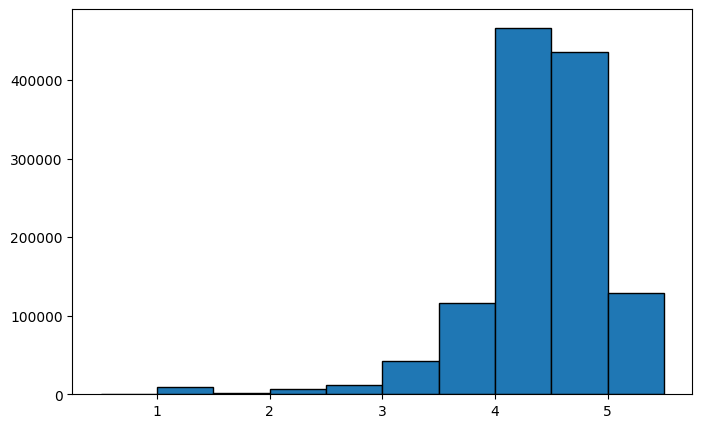

In [72]:
#plat histogram


plt.figure(figsize=(8, 5))
plt.hist(df["stars"], bins=np.arange(0.5, 5.6, 0.5), edgecolor="black")